# Assignment 2: Transfer Learning Across Two Datasets

**Name:** *Chase Krisko*

**Prerequisite:** Transfer Learning lecture (frozen feature extraction)

This assignment uses frozen transfer learning, exactly what was covered in lecture: load a pretrained base, freeze it, add a new head, train only that. You'll do this twice, on two different datasets, and compare the results.

Data loading is provided for you below. Everything after that, building the model, training, evaluating, and reflecting, is yours to write, following the general instructions in each section.

**Submission:** GitHub repo URL and this notebook's URL on Canvas.

## Setup — Imports

In [1]:
import tensorflow as tf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense
from tensorflow.keras.models import Model
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

---
# Part 1: Fire/Smoke Detection

## 1A — Load the Data

In [2]:
!pip install legacy-cgi --quiet
!pip install opendatasets --quiet

import opendatasets as od
od.download("https://www.kaggle.com/datasets/phylake1337/fire-dataset")

for root, dirs, files in os.walk("fire-dataset"):
    print(root, "->", dirs[:5], f"({len(files)} files)")

Please provide your Kaggle credentials to download this dataset. Learn more: http://bit.ly/kaggle-creds
Your Kaggle username: chasekrisko
Your Kaggle Key: ··········
Dataset URL: https://www.kaggle.com/datasets/phylake1337/fire-dataset


100%|██████████| 387M/387M [00:20<00:00, 20.0MB/s]



fire-dataset -> ['fire_dataset'] (0 files)
fire-dataset/fire_dataset -> ['non_fire_images', 'fire_images'] (0 files)
fire-dataset/fire_dataset/non_fire_images -> [] (244 files)
fire-dataset/fire_dataset/fire_images -> [] (755 files)


In [3]:
data_dir_fire = "fire-dataset/fire_dataset"

img_size = (224, 224)
batch_size = 32

train_raw_fire = tf.keras.utils.image_dataset_from_directory(
    data_dir_fire, image_size=img_size, batch_size=batch_size,
    validation_split=0.3, subset="training", seed=42, shuffle=True
)

val_test_raw_fire = tf.keras.utils.image_dataset_from_directory(
    data_dir_fire, image_size=img_size, batch_size=batch_size,
    validation_split=0.3, subset="validation", seed=42, shuffle=True
)

val_test_batches_fire = tf.data.experimental.cardinality(val_test_raw_fire)
test_raw_fire = val_test_raw_fire.take(val_test_batches_fire // 2)
val_raw_fire = val_test_raw_fire.skip(val_test_batches_fire // 2)

class_names_fire = train_raw_fire.class_names
print("Class names:", class_names_fire)

Found 999 files belonging to 2 classes.
Using 700 files for training.
Found 999 files belonging to 2 classes.
Using 299 files for validation.
Class names: ['fire_images', 'non_fire_images']


## 1B — Inspect the Data

Before doing anything else, take a real look at what you loaded. How many images does each class have? Is there anything about the data itself that might affect how you should split it, or how you should interpret your model's results later?

Write whatever code you need to answer this for yourself.

Number of fire images: 755 (75.6%)
Number of non-fire images: 244 (24.4%)
Total images: 999


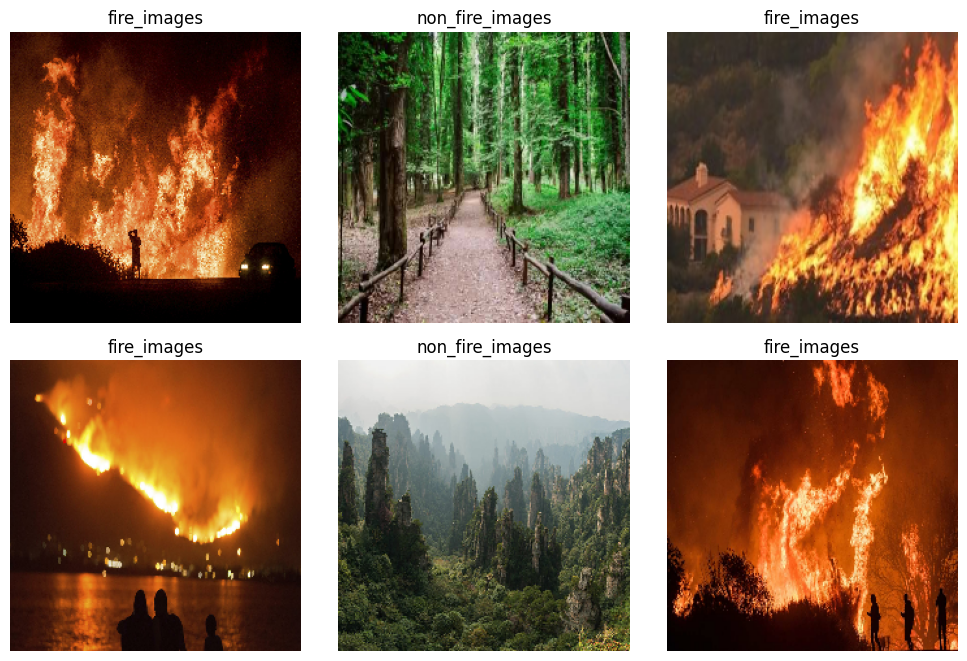

In [4]:

# Count the number of images
fire_dir = os.path.join(data_dir_fire, 'fire_images')
non_fire_dir = os.path.join(data_dir_fire, 'non_fire_images')

num_fire = len(os.listdir(fire_dir))
num_non_fire = len(os.listdir(non_fire_dir))
total_images = num_fire + num_non_fire

print(f"Number of fire images: {num_fire} ({num_fire/total_images:.1%})")
print(f"Number of non-fire images: {num_non_fire} ({num_non_fire/total_images:.1%})")
print(f"Total images: {total_images}")

# Display a few sample images from the training set
plt.figure(figsize=(10, 10))
for images, labels in train_raw_fire.take(1):
    for i in range(6):
        ax = plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names_fire[labels[i]])
        plt.axis("off")
plt.tight_layout()
plt.show()

*What did you notice about this dataset? Does it change how you'll approach the next steps?*

Looking at the dataset we see that fire pictures make up 75.6% and the non-fire images make up 24.4% of the images. This changes my next steps because I know that most of the images have fireso the model should predict more fire images than not.



## 1C — Build a Frozen Transfer Learning Model

Using MobileNetV2 as your pretrained base:
- Freeze the base model entirely
- Add a new output layer appropriate for this task (think about how many classes you're predicting, and what that means for your output layer's size, activation, and loss function)
- Remember the pattern from lecture for how the base model should be called

Preprocess your data (`train_raw_fire`, `val_raw_fire`, `test_raw_fire`) using MobileNetV2's expected preprocessing before building your model.

In [5]:
# Preprocess the data here
def preprocess_mobilenet(image, label):
    return preprocess_input(image), label

train_ds_fire = train_raw_fire.map(preprocess_mobilenet)
val_ds_fire = val_raw_fire.map(preprocess_mobilenet)
test_ds_fire = test_raw_fire.map(preprocess_mobilenet)


In [6]:
# Build your model here
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.layers import GlobalAveragePooling2D, Dropout, Dense
from tensorflow.keras.models import Model

base_model_mobilenet = MobileNetV2(include_top=False, weights='imagenet', input_shape=(224, 224, 3))
base_model_mobilenet.trainable = False  # Freeze the base


x = base_model_mobilenet.output
x = GlobalAveragePooling2D()(x)
# x = Dropout(0.3)(x)

output = Dense(1, activation='sigmoid')(x)

# Define the final model
mobilenet_model = Model(inputs=base_model_mobilenet.input, outputs=output)



9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


In [7]:
# Compile your model here
mobilenet_model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

mobilenet_model.summary()


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1 (Conv2D)      │ (None, 112, 112,  │        864 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn_Conv1            │ (None, 112, 112,  │        128 │ Conv1[0][0]       │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1_relu (ReLU)   │ (None, 112, 112,  │          0 │ bn_Conv1[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        288 │ Conv1_relu[0][0]  │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        128 │ expanded_conv_de… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │          0 │ expanded_conv_de… │
│ (ReLU)              │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │        512 │ expanded_conv_de… │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │         64 │ expanded_conv_pr… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand      │ (None, 112, 112,  │      1,536 │ expanded_conv_pr… │
│ (Conv2D)            │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_BN   │ (None, 112, 112,  │        384 │ block_1_expand[0… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_relu │ (None, 112, 112,  │          0 │ block_1_expand_B… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_pad         │ (None, 113, 113,  │          0 │ block_1_expand_r… │
│ (ZeroPadding2D)     │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise   │ (None, 56, 56,    │        864 │ block_1_pad[0][0] │
│ (DepthwiseConv2D)   │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │        384 │ block_1_depthwis… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │          0 │ block_1_depthwis… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_project     │ (None, 56, 56,    │      2,304 │ block_1_depthwis

 Total params: 2,259,265 (8.62 MB)

 Trainable params: 1,281 (5.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

## 1D — Train and Evaluate

In [8]:
# Train your model here

mobilenet_history = mobilenet_model.fit(
    train_ds_fire,
    validation_data=val_ds_fire,
    epochs=5
)

Epoch 1/5
22/22 ━━━━━━━━━━━━━━━━━━━━ 56s 2s/step - accuracy: 0.8014 - loss: 0.4012 - val_accuracy: 0.9281 - val_loss: 0.2321
Epoch 2/5
22/22 ━━━━━━━━━━━━━━━━━━━━ 57s 3s/step - accuracy: 0.9600 - loss: 0.1611 - val_accuracy: 0.9496 - val_loss: 0.1366
Epoch 3/5
22/22 ━━━━━━━━━━━━━━━━━━━━ 51s 2s/step - accuracy: 0.9743 - loss: 0.1101 - val_accuracy: 0.9640 - val_loss: 0.0964
Epoch 4/5
22/22 ━━━━━━━━━━━━━━━━━━━━ 49s 2s/step - accuracy: 0.9786 - loss: 0.0894 - val_accuracy: 0.9712 - val_loss: 0.0781
Epoch 5/5
22/22 ━━━━━━━━━━━━━━━━━━━━ 50s 2s/step - accuracy: 0.9829 - loss: 0.0771 - val_accuracy: 0.9856 - val_loss: 0.0711


In [9]:
# Report validation and test accuracy here

 # Evaluate on the validation dataset
val_loss, val_accuracy = mobilenet_model.evaluate(val_ds_fire, verbose=0)
print(f"Validation Accuracy: {val_accuracy:.4f}")

# Evaluate on the test dataset
test_loss, test_accuracy = mobilenet_model.evaluate(test_ds_fire, verbose=0)
print(f"Test Accuracy:       {test_accuracy:.4f}")

Validation Accuracy: 0.9640
Test Accuracy:       0.9812


## 1E — Confusion Matrix and Discussion

Build a confusion matrix for your model's test set predictions.

**Answer:** In this context, is a false negative (missing a real fire) or a false positive (a false alarm) more costly? How might that change the decision threshold you'd actually use in practice, rather than the default 0.5?

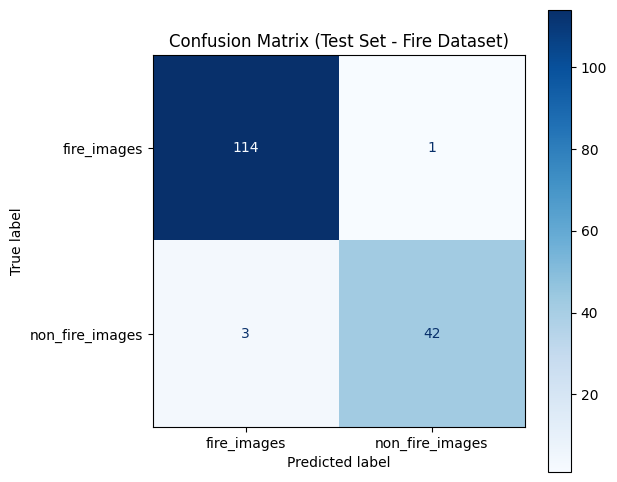

In [10]:
# 1. Gather all true labels and predictions from the test dataset
y_true = []
y_pred_probs = []

for images, labels in test_ds_fire:
    y_true.extend(labels.numpy())
    preds = mobilenet_model.predict(images, verbose=0)
    y_pred_probs.extend(preds.flatten())

y_true = np.array(y_true)
y_pred_probs = np.array(y_pred_probs)

# 2. Convert probabilities to binary predictions using the default threshold of 0.5
y_pred = (y_pred_probs >= 0.5).astype(int)

# 3. Generate and display the Confusion Matrix
cm = confusion_matrix(y_true, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names_fire)

fig, ax = plt.subplots(figsize=(6, 6))
disp.plot(cmap=plt.cm.Blues, ax=ax)
plt.title("Confusion Matrix (Test Set - Fire Dataset)")
plt.show()

*Your answer:*

A false negative (**FN**) would be more costly becauseafirethathas not been caught can cause environmental damage, property damage, and worst case senario a lost life. To fix these false negativesto save lives I would change thedefault threshold to .2 so if themodel thinksan imagemight have fire it would mark it as a fire image to keep people safe.


---
# Part 2: Satellite Land-Use Classification (EuroSAT)

## 2A — Load the Data

In [11]:
!wget -q "https://zenodo.org/records/7711810/files/EuroSAT_RGB.zip?download=1" -O EuroSAT_RGB.zip
!unzip -q EuroSAT_RGB.zip -d eurosat_data

data_dir_sat = "eurosat_data/EuroSAT_RGB"
print(os.listdir(data_dir_sat))

['HerbaceousVegetation', 'AnnualCrop', 'Highway', 'Pasture', 'River', 'Industrial', 'PermanentCrop', 'Residential', 'Forest', 'SeaLake']


In [12]:
train_raw_sat = tf.keras.utils.image_dataset_from_directory(
    data_dir_sat, image_size=img_size, batch_size=batch_size,
    validation_split=0.3, subset="training", seed=42, shuffle=True
)

val_test_raw_sat = tf.keras.utils.image_dataset_from_directory(
    data_dir_sat, image_size=img_size, batch_size=batch_size,
    validation_split=0.3, subset="validation", seed=42, shuffle=True
)

val_test_batches_sat = tf.data.experimental.cardinality(val_test_raw_sat)
test_raw_sat = val_test_raw_sat.take(val_test_batches_sat // 2)
val_raw_sat = val_test_raw_sat.skip(val_test_batches_sat // 2)

class_names_sat = train_raw_sat.class_names
print("Class names:", class_names_sat)

Found 27000 files belonging to 10 classes.
Using 18900 files for training.
Found 27000 files belonging to 10 classes.
Using 8100 files for validation.
Class names: ['AnnualCrop', 'Forest', 'HerbaceousVegetation', 'Highway', 'Industrial', 'Pasture', 'PermanentCrop', 'Residential', 'River', 'SeaLake']


## 2B — Build a Frozen Transfer Learning Model

Same overall pattern as Part 1, but look closely at what's different about this task before you build your output layer, activation, and loss function.

Preprocess `train_raw_sat`, `val_raw_sat`, and `test_raw_sat` first.

In [13]:
# Preprocess the data here
def preprocess_mobilenet(image, label):
    return preprocess_input(image), label

train_ds_sat = train_raw_sat.map(preprocess_mobilenet)
val_ds_sat = val_raw_sat.map(preprocess_mobilenet)
test_ds_sat = test_raw_sat.map(preprocess_mobilenet)


In [14]:
# Build your model here
base_model_sat = MobileNetV2(include_top=False, weights='imagenet', input_shape=(224, 224, 3))
base_model_sat.trainable = False

# Construct the head for 10-class classification
x = base_model_sat.output
x = GlobalAveragePooling2D()(x)
output_sat = Dense(10, activation='softmax')(x)

sat_model = Model(inputs=base_model_sat.input, outputs=output_sat)


In [15]:
# Compile your model here

sat_model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

sat_model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1 (Conv2D)      │ (None, 112, 112,  │        864 │ input_layer_1[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn_Conv1            │ (None, 112, 112,  │        128 │ Conv1[0][0]       │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1_relu (ReLU)   │ (None, 112, 112,  │          0 │ bn_Conv1[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        288 │ Conv1_relu[0][0]  │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        128 │ expanded_conv_de… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │          0 │ expanded_conv_de… │
│ (ReLU)              │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │        512 │ expanded_conv_de… │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │         64 │ expanded_conv_pr… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand      │ (None, 112, 112,  │      1,536 │ expanded_conv_pr… │
│ (Conv2D)            │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_BN   │ (None, 112, 112,  │        384 │ block_1_expand[0… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_relu │ (None, 112, 112,  │          0 │ block_1_expand_B… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_pad         │ (None, 113, 113,  │          0 │ block_1_expand_r… │
│ (ZeroPadding2D)     │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise   │ (None, 56, 56,    │        864 │ block_1_pad[0][0] │
│ (DepthwiseConv2D)   │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │        384 │ block_1_depthwis… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │          0 │ block_1_depthwis… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_project     │ (None, 56, 56,    │      2,304 │ block_1_depthwis

 Total params: 2,270,794 (8.66 MB)

 Trainable params: 12,810 (50.04 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

## 2C — Train and Evaluate

In [16]:
# Train your model here

sat_history = sat_model.fit(
    train_ds_sat,
    validation_data=val_ds_sat,
    epochs=5
)

Epoch 1/5
591/591 ━━━━━━━━━━━━━━━━━━━━ 974s 2s/step - accuracy: 0.8786 - loss: 0.3723 - val_accuracy: 0.9309 - val_loss: 0.2131
Epoch 2/5
591/591 ━━━━━━━━━━━━━━━━━━━━ 1012s 2s/step - accuracy: 0.9338 - loss: 0.1950 - val_accuracy: 0.9415 - val_loss: 0.1857
Epoch 3/5
591/591 ━━━━━━━━━━━━━━━━━━━━ 965s 2s/step - accuracy: 0.9471 - loss: 0.1589 - val_accuracy: 0.9390 - val_loss: 0.1812
Epoch 4/5
591/591 ━━━━━━━━━━━━━━━━━━━━ 983s 2s/step - accuracy: 0.9550 - loss: 0.1384 - val_accuracy: 0.9447 - val_loss: 0.1750
Epoch 5/5
591/591 ━━━━━━━━━━━━━━━━━━━━ 985s 2s/step - accuracy: 0.9612 - loss: 0.1216 - val_accuracy: 0.9410 - val_loss: 0.1756


In [17]:
# Report validation and test accuracy here

# Evaluate on the validation dataset
val_loss_sat, val_accuracy_sat = sat_model.evaluate(val_ds_sat, verbose=0)
print(f"Validation Accuracy: {val_accuracy_sat:.4f}")

# Evaluate on the test dataset
test_loss_sat, test_accuracy_sat = sat_model.evaluate(test_ds_sat, verbose=0)
print(f"Test Accuracy:       {test_accuracy_sat:.4f}")

Validation Accuracy: 0.9395
Test Accuracy:       0.9365


## 2D — Confusion Matrix and Discussion

Build a confusion matrix for your model's test set predictions.

**Answer:** Which land-use classes get confused most often? Does that make visual sense to you?

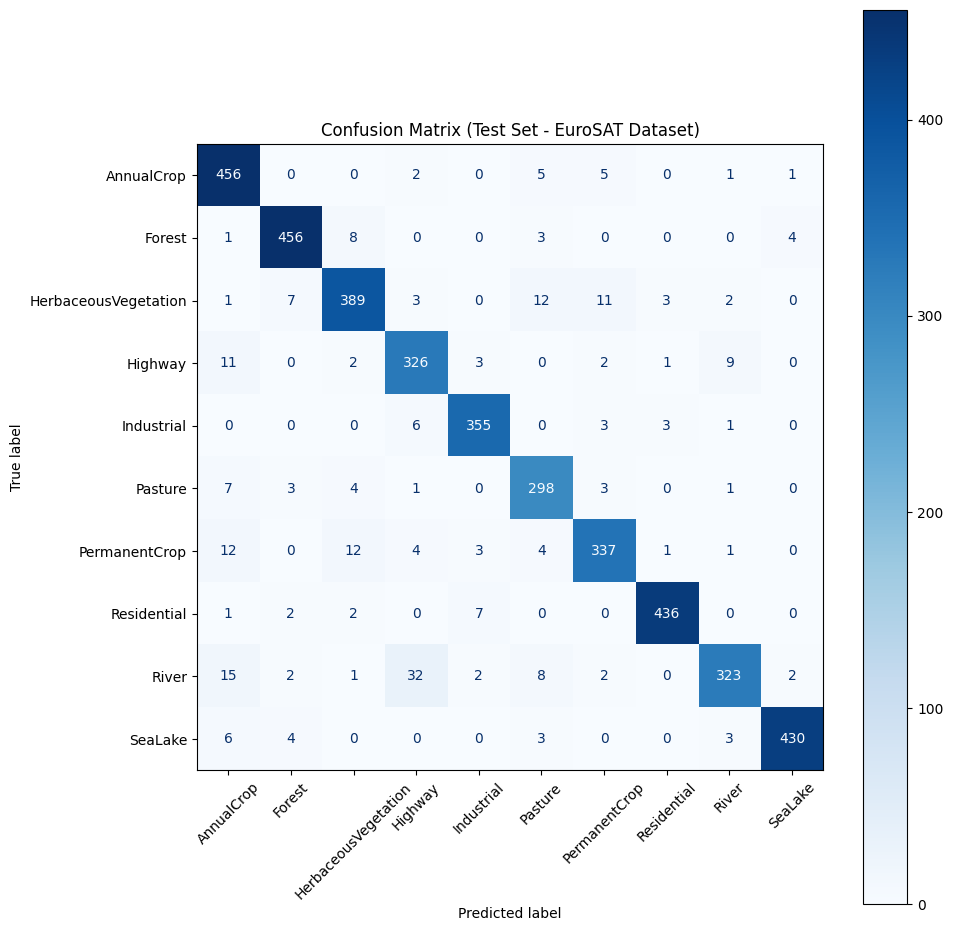

In [18]:
# Build your confusion matrix here

y_true_sat = []
y_pred_probs_sat = []

for images, labels in test_ds_sat:
    y_true_sat.extend(labels.numpy())
    preds = sat_model.predict(images, verbose=0)
    y_pred_probs_sat.extend(preds)

y_true_sat = np.array(y_true_sat)
y_pred_probs_sat = np.array(y_pred_probs_sat)

y_pred_sat = np.argmax(y_pred_probs_sat, axis=1)

cm_sat = confusion_matrix(y_true_sat, y_pred_sat)
fig, ax = plt.subplots(figsize=(10, 10))
disp_sat = ConfusionMatrixDisplay(confusion_matrix=cm_sat, display_labels=class_names_sat)
disp_sat.plot(cmap=plt.cm.Blues, ax=ax, xticks_rotation=45)
plt.title("Confusion Matrix (Test Set - EuroSAT Dataset)")
plt.tight_layout()
plt.show()

*Your answer:*
The land-use classes that get confused themost is River vs Highway, PermanentCrop vs AnnualCrop and HerbaceousVegitation, Herbaceous vs Pasture.

Yes this makes sense because through a satelight image a river and a highway look very similar. With the Crop and vegitation struggles that makessensebecause it's hard to tell whatcrop is annual, permenant, or herbaceous through a small satilight image.



---
# Part 3: Compare the Two Domains

Fill in your own results:

| | Fire/Smoke | EuroSAT |
|---|---|---|
| Validation Accuracy | 0.9640| 0.9395|
| Test Accuracy |  0.9812| 0.9365|

**Answer:**
1. MobileNetV2 was originally trained on ImageNet, ordinary ground-level photos of everyday objects. Which of your two datasets do you think is the closer match to that original training, and which is the bigger mismatch? Use your actual results as evidence.
2. For each dataset, do you think there's room for improvement if you could adjust part of the pretrained model itself, rather than just the new layer on top? Would you expect that to matter more for one dataset than the other? Why?



```
# This is formatted as code
```

*Your answers:*

1. The Fire/Smoke dataset is a much closer match to the original ImageNet training, while the EuroSAT dataset represents a major domain mismatch. ImageNet consists of ground-level photos of fire and non fire images scenes similar to how ground level fires, trees, and buildings are depicted in the Fire dataset. In contrast, EuroSAT consists of satellite imagery, which has entirely different angles, scales, and spatial structures. The results support this by the Fire/Smoke data set having validation score of .9640, and a accuracy score of .9812 which was more then the EuroSAT dataset.

2.
  Yes, there is significant room for improvement in both datasets by unfreezing and fine tuning the upper layers of the pretrained MobileNetV2 base. However, this fine tuning would matter more for the EuroSAT dataset, because satellite imagery is a completely different domain, the generic high-level features learned by MobileNetV2's deep layers on ImageNet do not fully capture satellite-specific patterns. Unfreezing the top layers would allow the feature extractors to specialize in satellite textures and structures. For the Fire dataset, the feature extractors are already highly compatible, so fine-tuning would only yield marginal gains.




---
# Part 4: Reflection

Answer in 4 to 6 sentences:

1. Did anything about the Fire dataset's composition affect how you approached splitting or evaluating it? Explain.
2. What's the actual difference between the output layer, activation, and loss function you used in Part 1 versus Part 2? Why does that difference exist?
3. Based on your results, does a pretrained model's usefulness depend only on how good the model is, or also on how well its original training matches your task? Explain using your own two results as evidence.

*Your answers:*



---
## Done!

Save this notebook back to your GitHub fork, then submit your two links on Canvas.